In [2]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
import os

project_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project'

print(os.listdir(project_path))

['PlantVillage file.zip', 'PlantVillage_Dataset', 'Potato_Disease_CNN_Model.keras']


In [1]:
import zipfile

zip_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/PlantVillage file.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    potato_files = [
        name for name in zip_ref.namelist()
        if 'Potato___' in name
    ]

print("Total Potato-related files:", len(potato_files))
print("\nFirst 15 files:")
for name in potato_files[:15]:
    print(name)

Total Potato-related files: 6456

First 15 files:
plantvillage dataset/color/Potato___Early_blight/001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG
plantvillage dataset/color/Potato___Early_blight/002a55fb-7a3d-4a3a-aca8-ce2d5ebc6925___RS_Early.B 8170.JPG
plantvillage dataset/color/Potato___Early_blight/009c8c31-f22d-4ffd-8f16-189c6f06c577___RS_Early.B 7885.JPG
plantvillage dataset/color/Potato___Early_blight/00d8f10f-5038-4e0f-bb58-0b885ddc0cc5___RS_Early.B 8722.JPG
plantvillage dataset/color/Potato___Early_blight/0182e991-97f0-4805-a1f7-6e1b4306d518___RS_Early.B 7015.JPG
plantvillage dataset/color/Potato___Early_blight/02578b86-b234-4ac0-9bc3-691b5610e2bf___RS_Early.B 7562.JPG
plantvillage dataset/color/Potato___Early_blight/0267d4ca-522e-4ca0-b1a2-ce925e5b54a2___RS_Early.B 7020.JPG
plantvillage dataset/color/Potato___Early_blight/028f9b73-142f-499a-9c7b-d7c1ed5e5506___RS_Early.B 8546.JPG
plantvillage dataset/color/Potato___Early_blight/034959c1-f1e8-4a79-a6d5-3c1d14efa2f3_

In [2]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/PlantVillage file.zip'

extract_path = '/content/Potato_Dataset'

classes = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    selected_files = []

    for file in zip_ref.namelist():
        for class_name in classes:
            folder = f'plantvillage dataset/color/{class_name}/'

            if file.startswith(folder) and not file.endswith('/'):
                selected_files.append(file)

    zip_ref.extractall(extract_path, selected_files)

print("Potato Dataset Extracted Successfully!")

for class_name in classes:
    folder_path = os.path.join(
        extract_path,
        'plantvillage dataset',
        'color',
        class_name
    )

    print(class_name, ":", len(os.listdir(folder_path)), "images")

Potato Dataset Extracted Successfully!
Potato___Early_blight : 1000 images
Potato___Late_blight : 1000 images
Potato___healthy : 152 images


In [3]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/PlantVillage file.zip'

extract_path = '/content/Potato_Dataset'

classes = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    selected_files = []

    for file in zip_ref.namelist():
        for class_name in classes:
            folder = f'plantvillage dataset/color/{class_name}/'

            if file.startswith(folder) and not file.endswith('/'):
                selected_files.append(file)

    zip_ref.extractall(extract_path, selected_files)

print("Potato Dataset Extracted Successfully!")

for class_name in classes:
    folder_path = os.path.join(
        extract_path,
        'plantvillage dataset',
        'color',
        class_name
    )

    print(class_name, ":", len(os.listdir(folder_path)), "images")

Potato Dataset Extracted Successfully!
Potato___Early_blight : 1000 images
Potato___Late_blight : 1000 images
Potato___healthy : 152 images


In [4]:
import os

dataset_path = '/content/Potato_Dataset/plantvillage dataset/color'

print("Dataset Classes:")

for class_name in os.listdir(dataset_path):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        print(class_name)

Dataset Classes:
Potato___Early_blight
Potato___healthy
Potato___Late_blight


In [5]:
import os

dataset_path = '/content/Potato_Dataset/plantvillage dataset/color'

total_images = 0

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        image_count = len([
            file for file in os.listdir(class_path)
            if file.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

        total_images += image_count

        print(class_name, ":", image_count, "images")

print("\nTotal Images:", total_images)

Potato___Early_blight : 1000 images
Potato___Late_blight : 1000 images
Potato___healthy : 152 images

Total Images: 2152


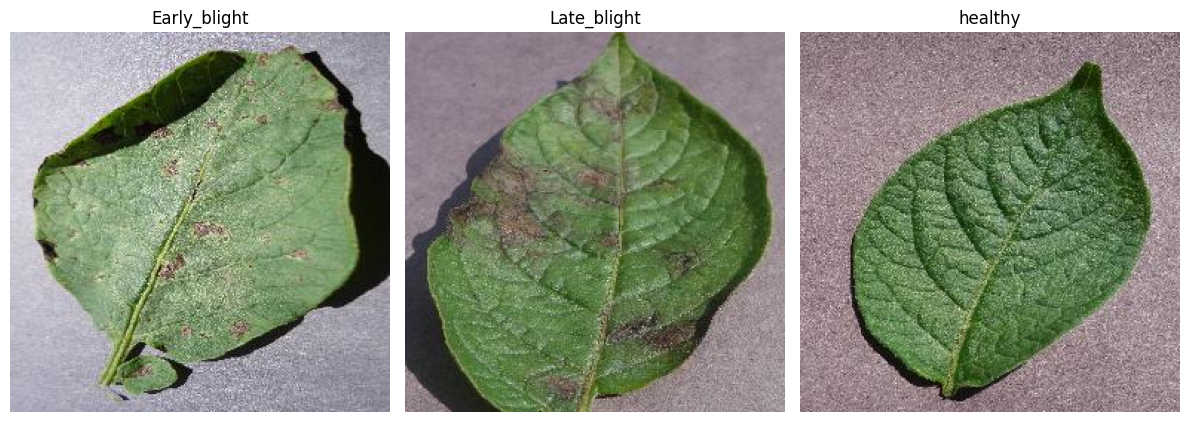

In [6]:
import matplotlib.pyplot as plt
import os
import random
from PIL import Image

dataset_path = '/content/Potato_Dataset/plantvillage dataset/color'

classes = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name.replace('Potato___', ''))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
import tensorflow as tf

dataset_path = '/content/Potato_Dataset/plantvillage dataset/color'

# Image settings
img_height = 128
img_width = 128
batch_size = 32
seed = 42

# Training Dataset (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Validation Dataset (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

print("\nTraining Classes:", train_ds.class_names)
print("Validation Classes:", val_ds.class_names)

print("\nTraining Batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation Batches:", tf.data.experimental.cardinality(val_ds).numpy())

Found 2152 files belonging to 3 classes.
Using 1722 files for training.
Found 2152 files belonging to 3 classes.
Using 430 files for validation.

Training Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Validation Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

Training Batches: 54
Validation Batches: 14


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset Optimization Completed Successfully!")

Dataset Optimization Completed Successfully!


In [9]:
import numpy as np

class_counts = np.zeros(3, dtype=int)

for images, labels in train_ds:
    class_counts += np.bincount(
        labels.numpy(),
        minlength=3
    )

total_samples = np.sum(class_counts)
num_classes = 3

class_weights = {
    i: total_samples / (num_classes * count)
    for i, count in enumerate(class_counts)
}

print("Training Class Counts:")

for i, class_name in enumerate([
    'Early Blight',
    'Late Blight',
    'Healthy'
]):
    print(class_name, ":", class_counts[i])

print("\nCalculated Class Weights:")
print(class_weights)

Training Class Counts:
Early Blight : 818
Late Blight : 792
Healthy : 112

Calculated Class Weights:
{0: np.float64(0.7017114914425427), 1: np.float64(0.7247474747474747), 2: np.float64(5.125)}


In [10]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(3, activation='softmax')
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [14]:
epochs = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    class_weight=class_weights
)

print("CNN Model Training Completed Successfully!")

Epoch 1/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 26s 261ms/step - accuracy: 0.4501 - loss: 1.0120 - val_accuracy: 0.7070 - val_loss: 0.6380
Epoch 2/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7236 - loss: 0.5247 - val_accuracy: 0.8930 - val_loss: 0.2853
Epoch 3/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8339 - loss: 0.3864 - val_accuracy: 0.8140 - val_loss: 0.4653
Epoch 4/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8293 - loss: 0.3701 - val_accuracy: 0.7372 - val_loss: 0.5366
Epoch 5/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8839 - loss: 0.2568 - val_accuracy: 0.9395 - val_loss: 0.1613
Epoch 6/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.9315 - loss: 0.1920 - val_accuracy: 0.7977 - val_loss: 0.4916
Epoch 7/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8653 - loss: 0.3065 - val_accuracy: 0.9372 - val_loss: 0.1617
Epoch 8/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9367 - loss: 0.1567 - val_accuracy: 0.9372 -

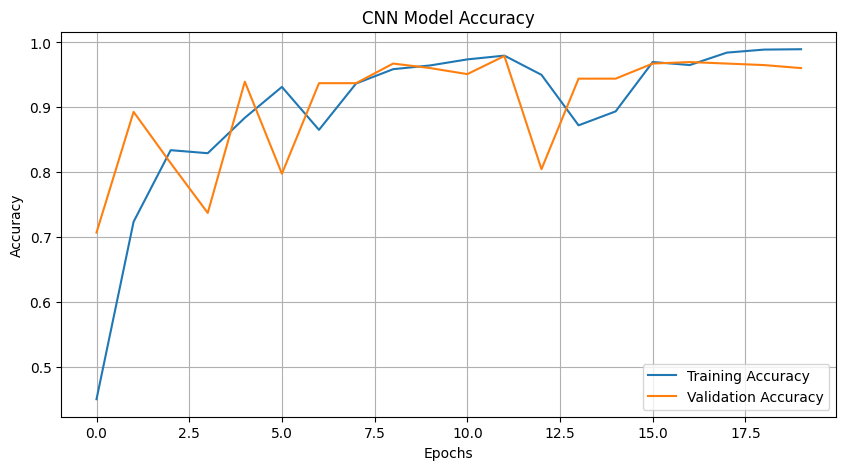

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()

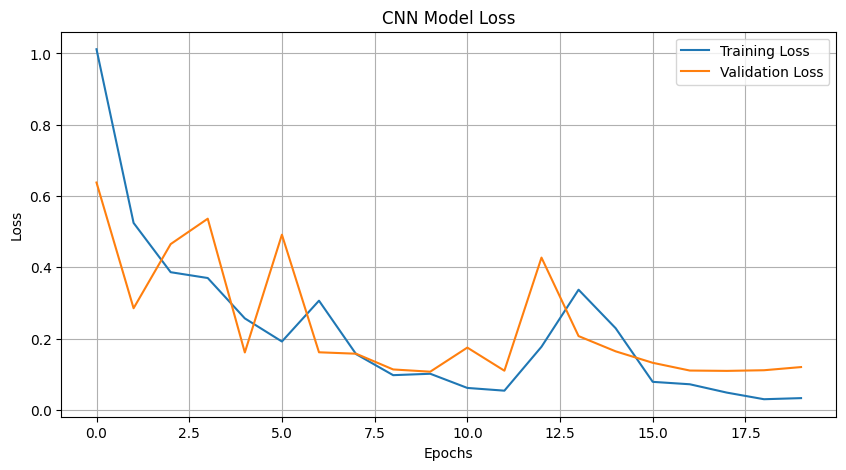

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()

In [17]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("\nModel Evaluation Results:")
print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy * 100, "%")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9605 - loss: 0.1203

Model Evaluation Results:
Validation Loss: 0.12026368826627731
Validation Accuracy: 96.0465133190155 %


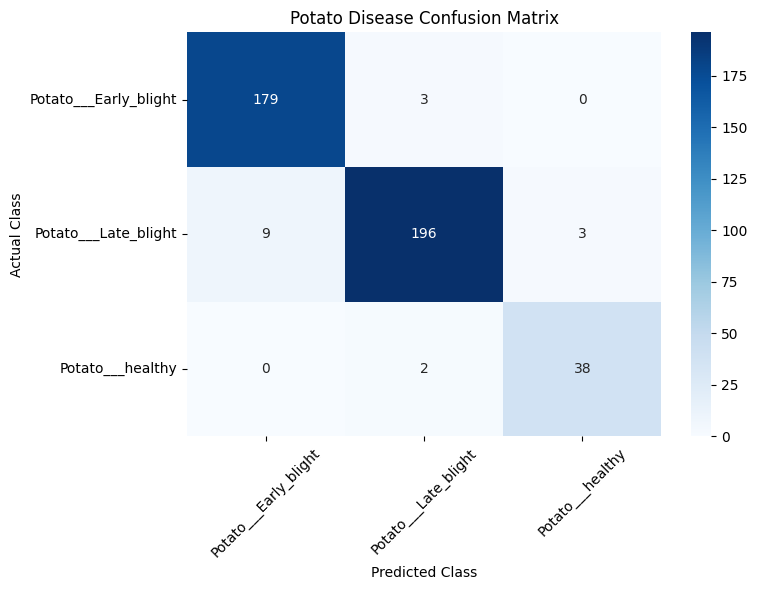


Classification Report:

                       precision    recall  f1-score   support

Potato___Early_blight       0.95      0.98      0.97       182
 Potato___Late_blight       0.98      0.94      0.96       208
     Potato___healthy       0.93      0.95      0.94        40

             accuracy                           0.96       430
            macro avg       0.95      0.96      0.95       430
         weighted avg       0.96      0.96      0.96       430



In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

# Class names
class_names = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy'
]

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Potato Disease Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

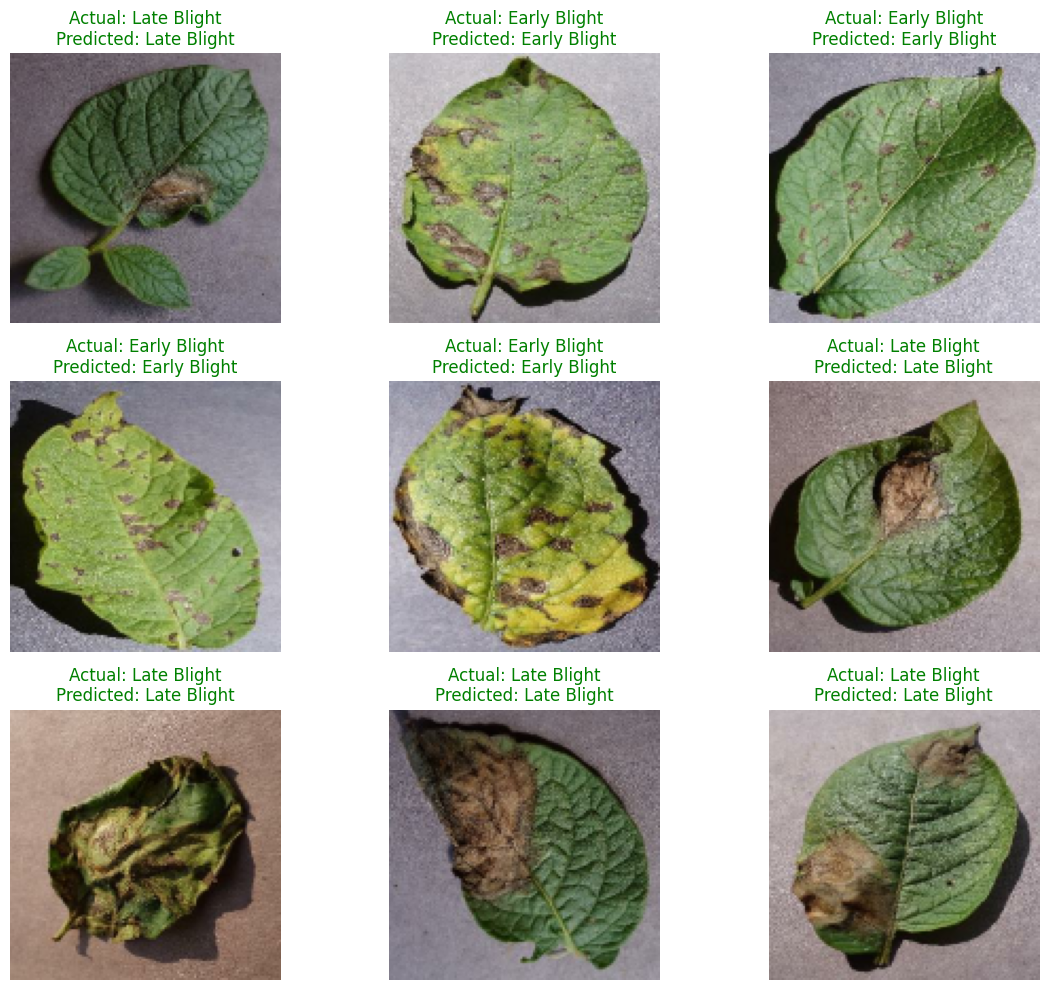

In [20]:
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    'Early Blight',
    'Late Blight',
    'Healthy'
]

plt.figure(figsize=(12, 10))

for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        actual = class_names[labels[i].numpy()]
        predicted = class_names[np.argmax(predictions[i])]

        color = 'green' if actual == predicted else 'red'

        plt.title(
            f"Actual: {actual}\nPredicted: {predicted}",
            color=color
        )

        plt.axis('off')

plt.tight_layout()
plt.show()

In [21]:
model.save('/content/Potato_Disease_CNN_Model.keras')

print("Potato Disease CNN Model Saved Successfully!")

Potato Disease CNN Model Saved Successfully!


In [22]:
import shutil

source_path = '/content/Potato_Disease_CNN_Model.keras'

drive_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/Potato_Disease_CNN_Model.keras'

shutil.copy(source_path, drive_path)

print("Model Successfully Saved to Google Drive!")
print("File Location:", drive_path)

Model Successfully Saved to Google Drive!
File Location: /content/drive/MyDrive/Potato_Disease_CNN_Project/Potato_Disease_CNN_Model.keras


In [23]:
import os

model_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/Potato_Disease_CNN_Model.keras'

if os.path.exists(model_path):
    print("Model File Verified Successfully!")
    print("File Size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model File Not Found!")

Model File Verified Successfully!
File Size: 37.87 MB


In [24]:
from tensorflow.keras.models import load_model

saved_model = load_model(
    '/content/drive/MyDrive/Potato_Disease_CNN_Project/Potato_Disease_CNN_Model.keras'
)

print("Saved CNN Model Loaded Successfully!")

Saved CNN Model Loaded Successfully!


In [25]:
test_loss, test_accuracy = saved_model.evaluate(val_ds)

print("\nLoaded Model Test Results:")
print("Accuracy:", round(test_accuracy * 100, 2), "%")
print("Loss:", round(test_loss, 4))

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9605 - loss: 0.1203

Loaded Model Test Results:
Accuracy: 96.05 %
Loss: 0.1203


In [55]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/PlantVillage file.zip'

test_folder = '/content/Potato_Test_Images'
os.makedirs(test_folder, exist_ok=True)

image_paths = {
    'Early Blight': 'plantvillage dataset/color/Potato___Early_blight/001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG',
    'Late Blight': 'plantvillage dataset/color/Potato___Late_blight/0051e5e8-d1c4-4a84-bf3a-a426cdad6285___RS_LB 4640.JPG',
    'Healthy': 'plantvillage dataset/color/Potato___healthy/00fc2ee5-729f-4757-8aeb-65c3355874f2___RS_HL 1864.JPG'
}

with zipfile.ZipFile(zip_path, 'r') as z:
    for class_name, file_path in image_paths.items():
        output_path = os.path.join(test_folder, class_name.replace(' ', '_') + '.JPG')

        with z.open(file_path) as source:
            with open(output_path, 'wb') as target:
                target.write(source.read())

        print(class_name, "Image Extracted Successfully!")

print("\nTotal Test Images:", len(os.listdir(test_folder)))

Early Blight Image Extracted Successfully!
Late Blight Image Extracted Successfully!
Healthy Image Extracted Successfully!

Total Test Images: 3



Actual Image: Early Blight.JPG


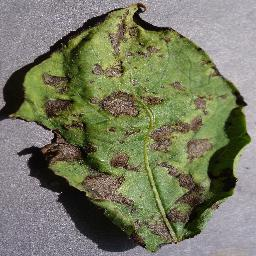

Predicted Class: Early Blight
Confidence: 100.0 %
Class-wise Probabilities:
Early Blight : 100.0 %
Late Blight : 0.0 %
Healthy : 0.0 %
-----------------------------------

Actual Image: Healthy.JPG


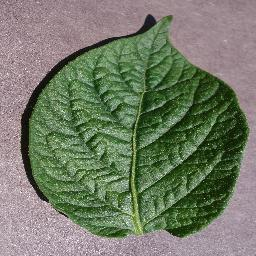

Predicted Class: Healthy
Confidence: 100.0 %
Class-wise Probabilities:
Early Blight : 0.0 %
Late Blight : 0.0 %
Healthy : 100.0 %
-----------------------------------

Actual Image: Late Blight.JPG


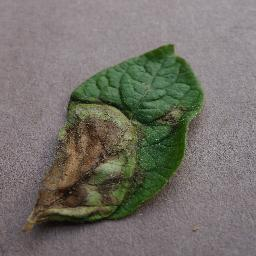

Predicted Class: Late Blight
Confidence: 100.0 %
Class-wise Probabilities:
Early Blight : 0.0 %
Late Blight : 100.0 %
Healthy : 0.0 %
-----------------------------------


In [56]:
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from IPython.display import display
from PIL import Image

model_path = '/content/drive/MyDrive/Potato_Disease_CNN_Project/Potato_Disease_CNN_Model.keras'

saved_model = load_model(model_path)

test_folder = '/content/Potato_Test_Images'

class_names = ['Early Blight', 'Late Blight', 'Healthy']

for file_name in os.listdir(test_folder):

    img_path = os.path.join(test_folder, file_name)

    img = image.load_img(img_path, target_size=(128, 128))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = saved_model.predict(img_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    confidence = predictions[0][predicted_index] * 100

    print("\nActual Image:", file_name.replace('_', ' '))
    display(Image.open(img_path))

    print("Predicted Class:", class_names[predicted_index])
    print("Confidence:", round(float(confidence), 2), "%")

    print("Class-wise Probabilities:")
    for i, name in enumerate(class_names):
        print(name, ":", round(float(predictions[0][i] * 100), 2), "%")

    print("-----------------------------------")